In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from typing import Sequence, Optional, Dict, Literal, Tuple, List
from model_ranking.results import load_transfer_metric_results
from model_ranking.utils import aug_name_to_sigma_tuple, add_decimal
from model_ranking.correlation import calculate_correlation_statistics
from model_ranking.dataclass import transferability_metric_names

INFO: P [MainThread] 2026-08-21 14:15:20,081 plantseg - Logger configured at initialisation. PlantSeg logger name: plantseg


/g/kreshuk/talks/pytorch-3dunet/pytorch3dunet/unet3d/utils.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/g/kreshuk/talks/miniforge3/envs/model-rank-local2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def plot_cmb_classification_seg_transfer_metric_correlations_CVPR(
    classification_results_path: Path,
    transfer_metrics: Sequence[str],
    nrows: int = 2,
    ncols: int = 4,
    figsize: Tuple[int, int] = (20, 10),
    save_path: Optional[Path] = None,
    point_size: int = 100,
    consistency_class_results_path: Optional[Path] = None,
    consis_class_aug_str: Optional[str] = None,
    CMR_metric_keys: Optional[Sequence[str]] = None,
    inverted_transfer_metrics: Optional[Sequence[str]] = None,
    scores_fontsize: int = 12,
    title_fontsize: int = 16,
    label_fontsize: int = 14,
    ticks_fontsize: int = 12,
    title_bold: bool = True,
    custom_legend_labels: Optional[Dict[str, str]] = None,
):
    """Create classification transfer-metric correlation plots per target dataset.

    Model architecture is encoded by marker shape and source dataset by color.
    CMR metrics must be named ``CMR-<key>`` and each key must be provided in
    ``CMR_metric_keys``. Metrics included in ``inverted_transfer_metrics`` are
    plotted and correlated as ``1 - score``.
    """

    transfer_metrics = sorted(transfer_metrics)
    classification_data: Dict[str, Dict[str, Dict[str, Dict[str, float]]]] = {}
    cmr_metric_keys = set(CMR_metric_keys or [])
    inverted_metrics = set(inverted_transfer_metrics or [])

    for metric in transfer_metrics:
        if metric.startswith("CMR-"):
            cmr_metric_key = metric.removeprefix("CMR-")
            assert cmr_metric_key in cmr_metric_keys, (
                f"CMR key '{cmr_metric_key}' must be included in CMR_metric_keys"
            )
            assert (
                consistency_class_results_path is not None
            ), "path to consistency classification results must be provided"
            assert (
                consis_class_aug_str is not None
            ), "selected classification augmentation strength must be provided"

            class_perf_path = (
                consistency_class_results_path / "transfer_performance_F1_scores.json"
            )
            class_perf_scores = load_transfer_metric_results(class_perf_path)
            class_consis_path = (
                consistency_class_results_path.parent
                / cmr_metric_key
                / f"transfer_Gauss_{consis_class_aug_str}_{cmr_metric_key}_scores.json"
            )
            class_consis_scores = load_transfer_metric_results(class_consis_path)
            classification_data[metric] = {**class_perf_scores, **class_consis_scores}
        else:
            class_path = classification_results_path / f"{metric}.json"
            classification_data[metric] = load_transfer_metric_results(class_path)

    targets = next(
        result["metadata"]["targets"]
        for result in classification_data.values()
        if "metadata" in result
    )

    architecture_markers = {
        "DenseNet121": "o",
        "MobileNetV2": "s",
        "MobileNetV3": "^",
        "ResNet18": "D",
        "ResNet50": "P",
    }
    source_colors = {
        "EPFL": "#377eb8",
        "Hmito": "#ff7f00",
        "Rmito": "#2ca02c",
    }
    architecture_order = list(architecture_markers)
    source_order = list(source_colors)

    def model_style(model_name: str) -> Tuple[str, str]:
        architecture, source = model_name.rsplit("_", maxsplit=1)
        return architecture_markers[architecture], source_colors.get(source, "gray")

    def model_sort_key(model_name: str) -> Tuple[int, int, str]:
        architecture, source = model_name.rsplit("_", maxsplit=1)
        return (
            architecture_order.index(architecture),
            source_order.index(source) if source in source_order else len(source_order),
            model_name,
        )

    for target in targets:
        fig, axes = plt.subplots(  # pyright: ignore
            nrows=nrows, ncols=ncols, figsize=figsize
        )
        axes = axes.flatten() if nrows * ncols > 1 else [axes]  # pyright: ignore
        legend_models: set[str] = set()

        for idx, metric in enumerate(transfer_metrics):
            if idx >= len(axes):  # pyright: ignore
                break

            ax = axes[idx]  # pyright: ignore
            class_transfer_scores = classification_data[metric]["transfer_scores"][
                target
            ]
            class_performance_scores = classification_data[metric][
                "performance_scores"
            ][target]
            model_names = sorted(
                (
                    model_name
                    for model_name in set(class_transfer_scores)
                    & set(class_performance_scores)
                    if model_name.rsplit("_", maxsplit=1)[0] in architecture_markers
                ),
                key=model_sort_key,
            )
            legend_models.update(model_names)
            invert_metric = metric in inverted_metrics
            display_metric = f"1 - {metric}" if invert_metric else metric
            class_x = np.array(
                [
                    1 - class_transfer_scores[model]
                    if invert_metric
                    else class_transfer_scores[model]
                    for model in model_names
                ]
            )
            class_y = np.array([class_performance_scores[model] for model in model_names])

            for model_index, model_name in enumerate(model_names):
                marker, color = model_style(model_name)
                _ = ax.scatter(  # pyright: ignore
                    class_x[model_index],
                    class_y[model_index],
                    marker=marker,
                    color=color,
                    edgecolors="black",
                    s=point_size,
                    linewidths=0.8,
                    alpha=0.7,
                )

            # _ = ax.set_title(
            #     display_metric,
            #     fontsize=title_fontsize,
            #     fontweight=("bold" if title_bold else "normal"),
            # )
            _ = ax.set_xlabel(  # pyright: ignore
                f"{display_metric}", fontsize=label_fontsize
            )
            _ = ax.set_ylabel(  # pyright: ignore
                "Performance Score (F1)", fontsize=label_fontsize
            )
            _ = ax.tick_params(  # pyright: ignore
                axis="both", which="major", labelsize=ticks_fontsize
            )

            class_transfer_array = class_x.reshape(-1, 1)
            class_kt_scores, class_sp_scores, class_pearson_scores = (
                calculate_correlation_statistics(class_transfer_array, class_y)
            )
            class_pr = class_pearson_scores[0, 0]
            class_sp = class_sp_scores[0, 0]
            class_kt = class_kt_scores[0, 0]
            corr_text = (
                f"K$\\tau$: {class_kt:.2f}\n"
                f"S$\\rho$: {class_sp:.2f}\n"
                f"Pr: {class_pr:.2f}"
            )
            _ = ax.text(  # pyright: ignore
                0.97,
                0.03,
                corr_text,
                transform=ax.transAxes,
                fontsize=scores_fontsize,
                verticalalignment="bottom",
                horizontalalignment="right",
                bbox=dict(
                    boxstyle="round,pad=0.5",
                    facecolor="white",
                    edgecolor="black",
                    alpha=0.9,
                    linestyle="--",
                    linewidth=1.5,
                ),
            )
            _ = ax.grid(True, alpha=0.5)  # pyright: ignore

        for idx in range(len(transfer_metrics), len(axes)):  # pyright: ignore
            axes[idx].set_visible(False)  # pyright: ignore

        legend_handles = []
        for model_name in sorted(legend_models, key=model_sort_key):
            marker, color = model_style(model_name)
            label = (
                custom_legend_labels.get(model_name, model_name)
                if custom_legend_labels is not None
                else model_name
            )
            legend_handles.append(
                Line2D(
                    [0],
                    [0],
                    marker=marker,
                    color="w",
                    markerfacecolor=color,
                    markeredgecolor="black",
                    markersize=10,
                    label=label,
                    linewidth=0,
                )
            )
        _ = fig.legend(
            handles=legend_handles,
            loc="center left",
            bbox_to_anchor=(0.88, 0.5),
            fontsize=scores_fontsize,
            title="Source dataset and architecture",
            title_fontsize=scores_fontsize,
            frameon=True,
        )

        _ = fig.suptitle(
            f"Classification Transfer Metrics vs Performance - Target: {target}",
            fontsize=16,
            fontweight="bold",
            y=0.995,
        )
        plt.tight_layout(rect=[0, 0, 0.86, 0.97])  # pyright: ignore

        if save_path is not None:
            save_path.mkdir(parents=True, exist_ok=True)
            fig_path_png = save_path / f"classification_metrics_{target}.png"
            plt.savefig(fig_path_png, dpi=300, bbox_inches="tight")
            print(f"Saved figure to: {fig_path_png}")
            fig_path_svg = save_path / f"classification_metrics_{target}.svg"
            plt.savefig(fig_path_svg, bbox_inches="tight")
            print(f"Saved figure to: {fig_path_svg}")

        plt.show()

    return None

In [3]:
custom_labels = {
    "DenseNet121_EPFL": "EPFL DenseNet121",
    "DenseNet121_Hmito": "Hmito DenseNet121",
    "DenseNet121_Rmito": "Rmito DenseNet121",
    "MobileNetV2_EPFL": "EPFL MobileNetV2",
    "MobileNetV2_Hmito": "Hmito MobileNetV2",
    "MobileNetV2_Rmito": "Rmito MobileNetV2",
    "MobileNetV3_EPFL": "EPFL MobileNetV3",
    "MobileNetV3_Hmito": "Hmito MobileNetV3",
    "MobileNetV3_Rmito": "Rmito MobileNetV3",
    "ResNet18_EPFL": "EPFL ResNet18",
    "ResNet18_Hmito": "Hmito ResNet18",
    "ResNet18_Rmito": "Rmito ResNet18",
    "ResNet50_EPFL": "EPFL ResNet50",
    "ResNet50_Hmito": "Hmito ResNet50",
    "ResNet50_Rmito": "Rmito ResNet50"
}


Loaded Transfer metric results from: /g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/consistency/EI/transfer_performance_F1_scores.json
Loaded Transfer metric results from: /g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/consistency/EI/transfer_Gauss_a005-01_EI_scores.json
Loaded Transfer metric results from: /g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/consistency/EI/transfer_performance_F1_scores.json
Loaded Transfer metric results from: /g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/consistency/NHD/transfer_Gauss_a005-01_NHD_scores.json
Loaded Transfer metric results from: /g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/fullset_results2/Dispersion.json
Experiment: _Dispersion
Targets: 3 (EPFL, Hmito, Rmito)
Source models: 14
Total transfers: 42
Loaded Transfer metric results from: /g/kreshuk/

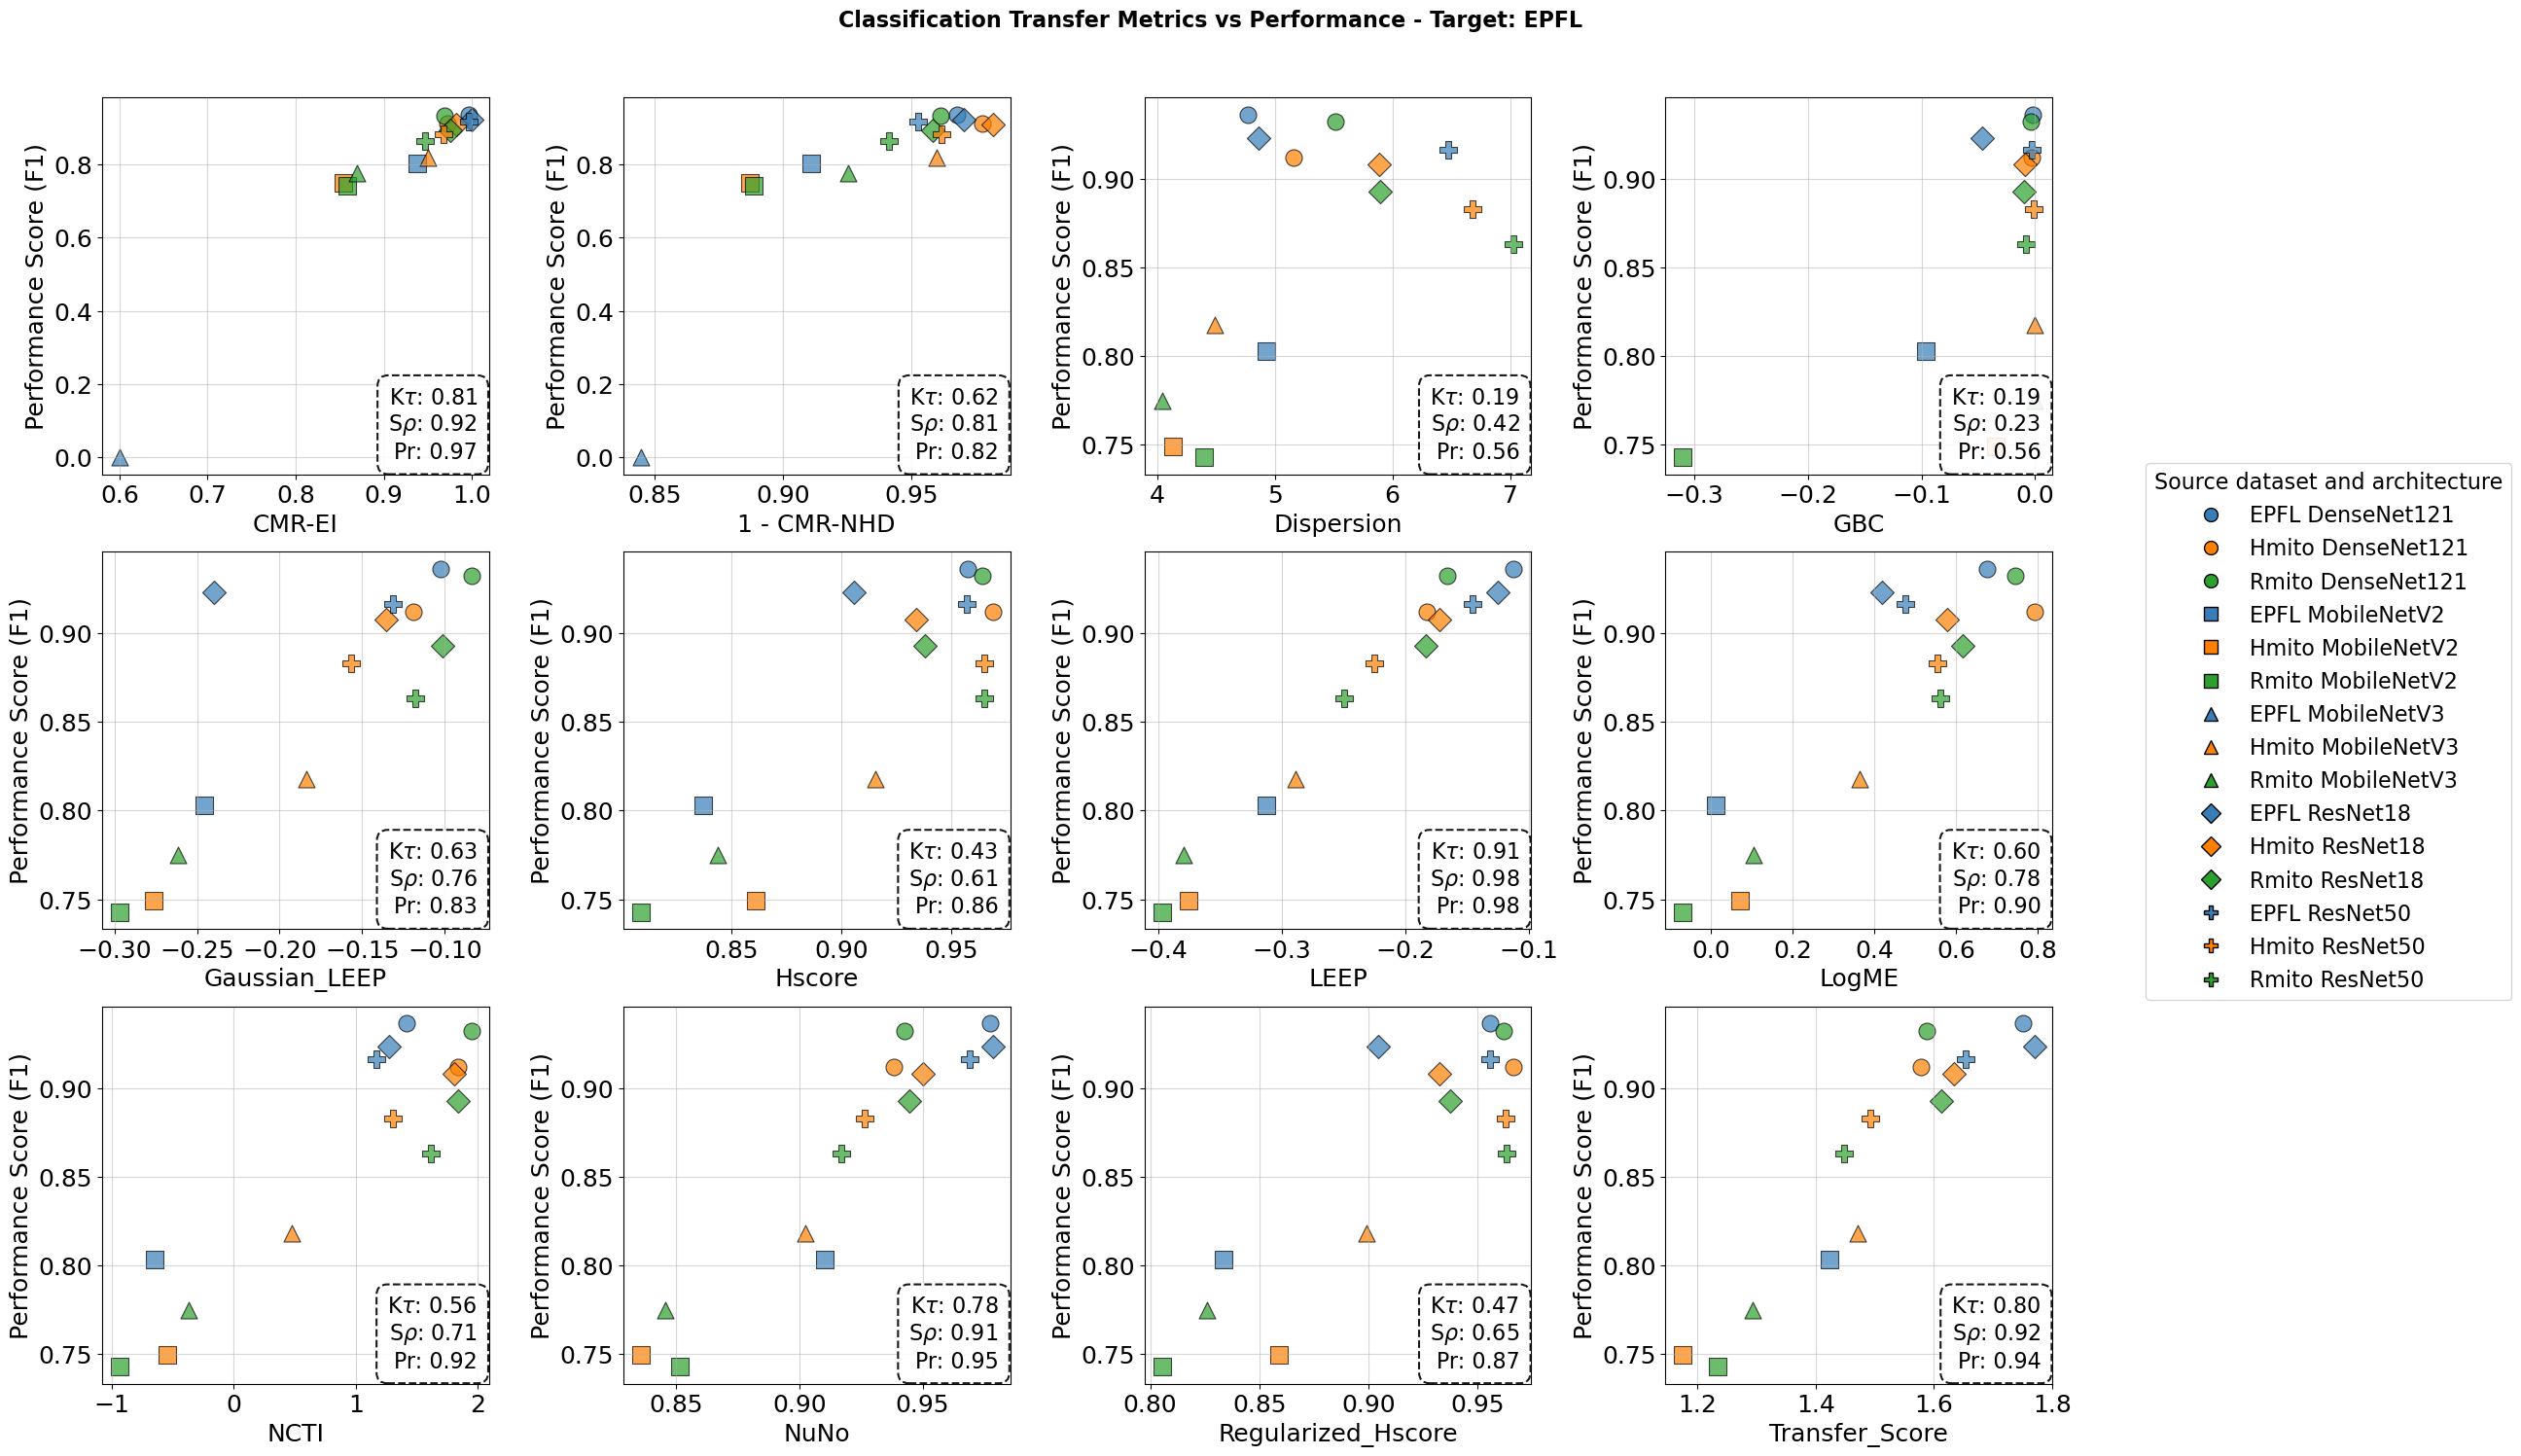

Saved figure to: /g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/extended_005-01/classification_metrics_Hmito.png
Saved figure to: /g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/extended_005-01/classification_metrics_Hmito.svg


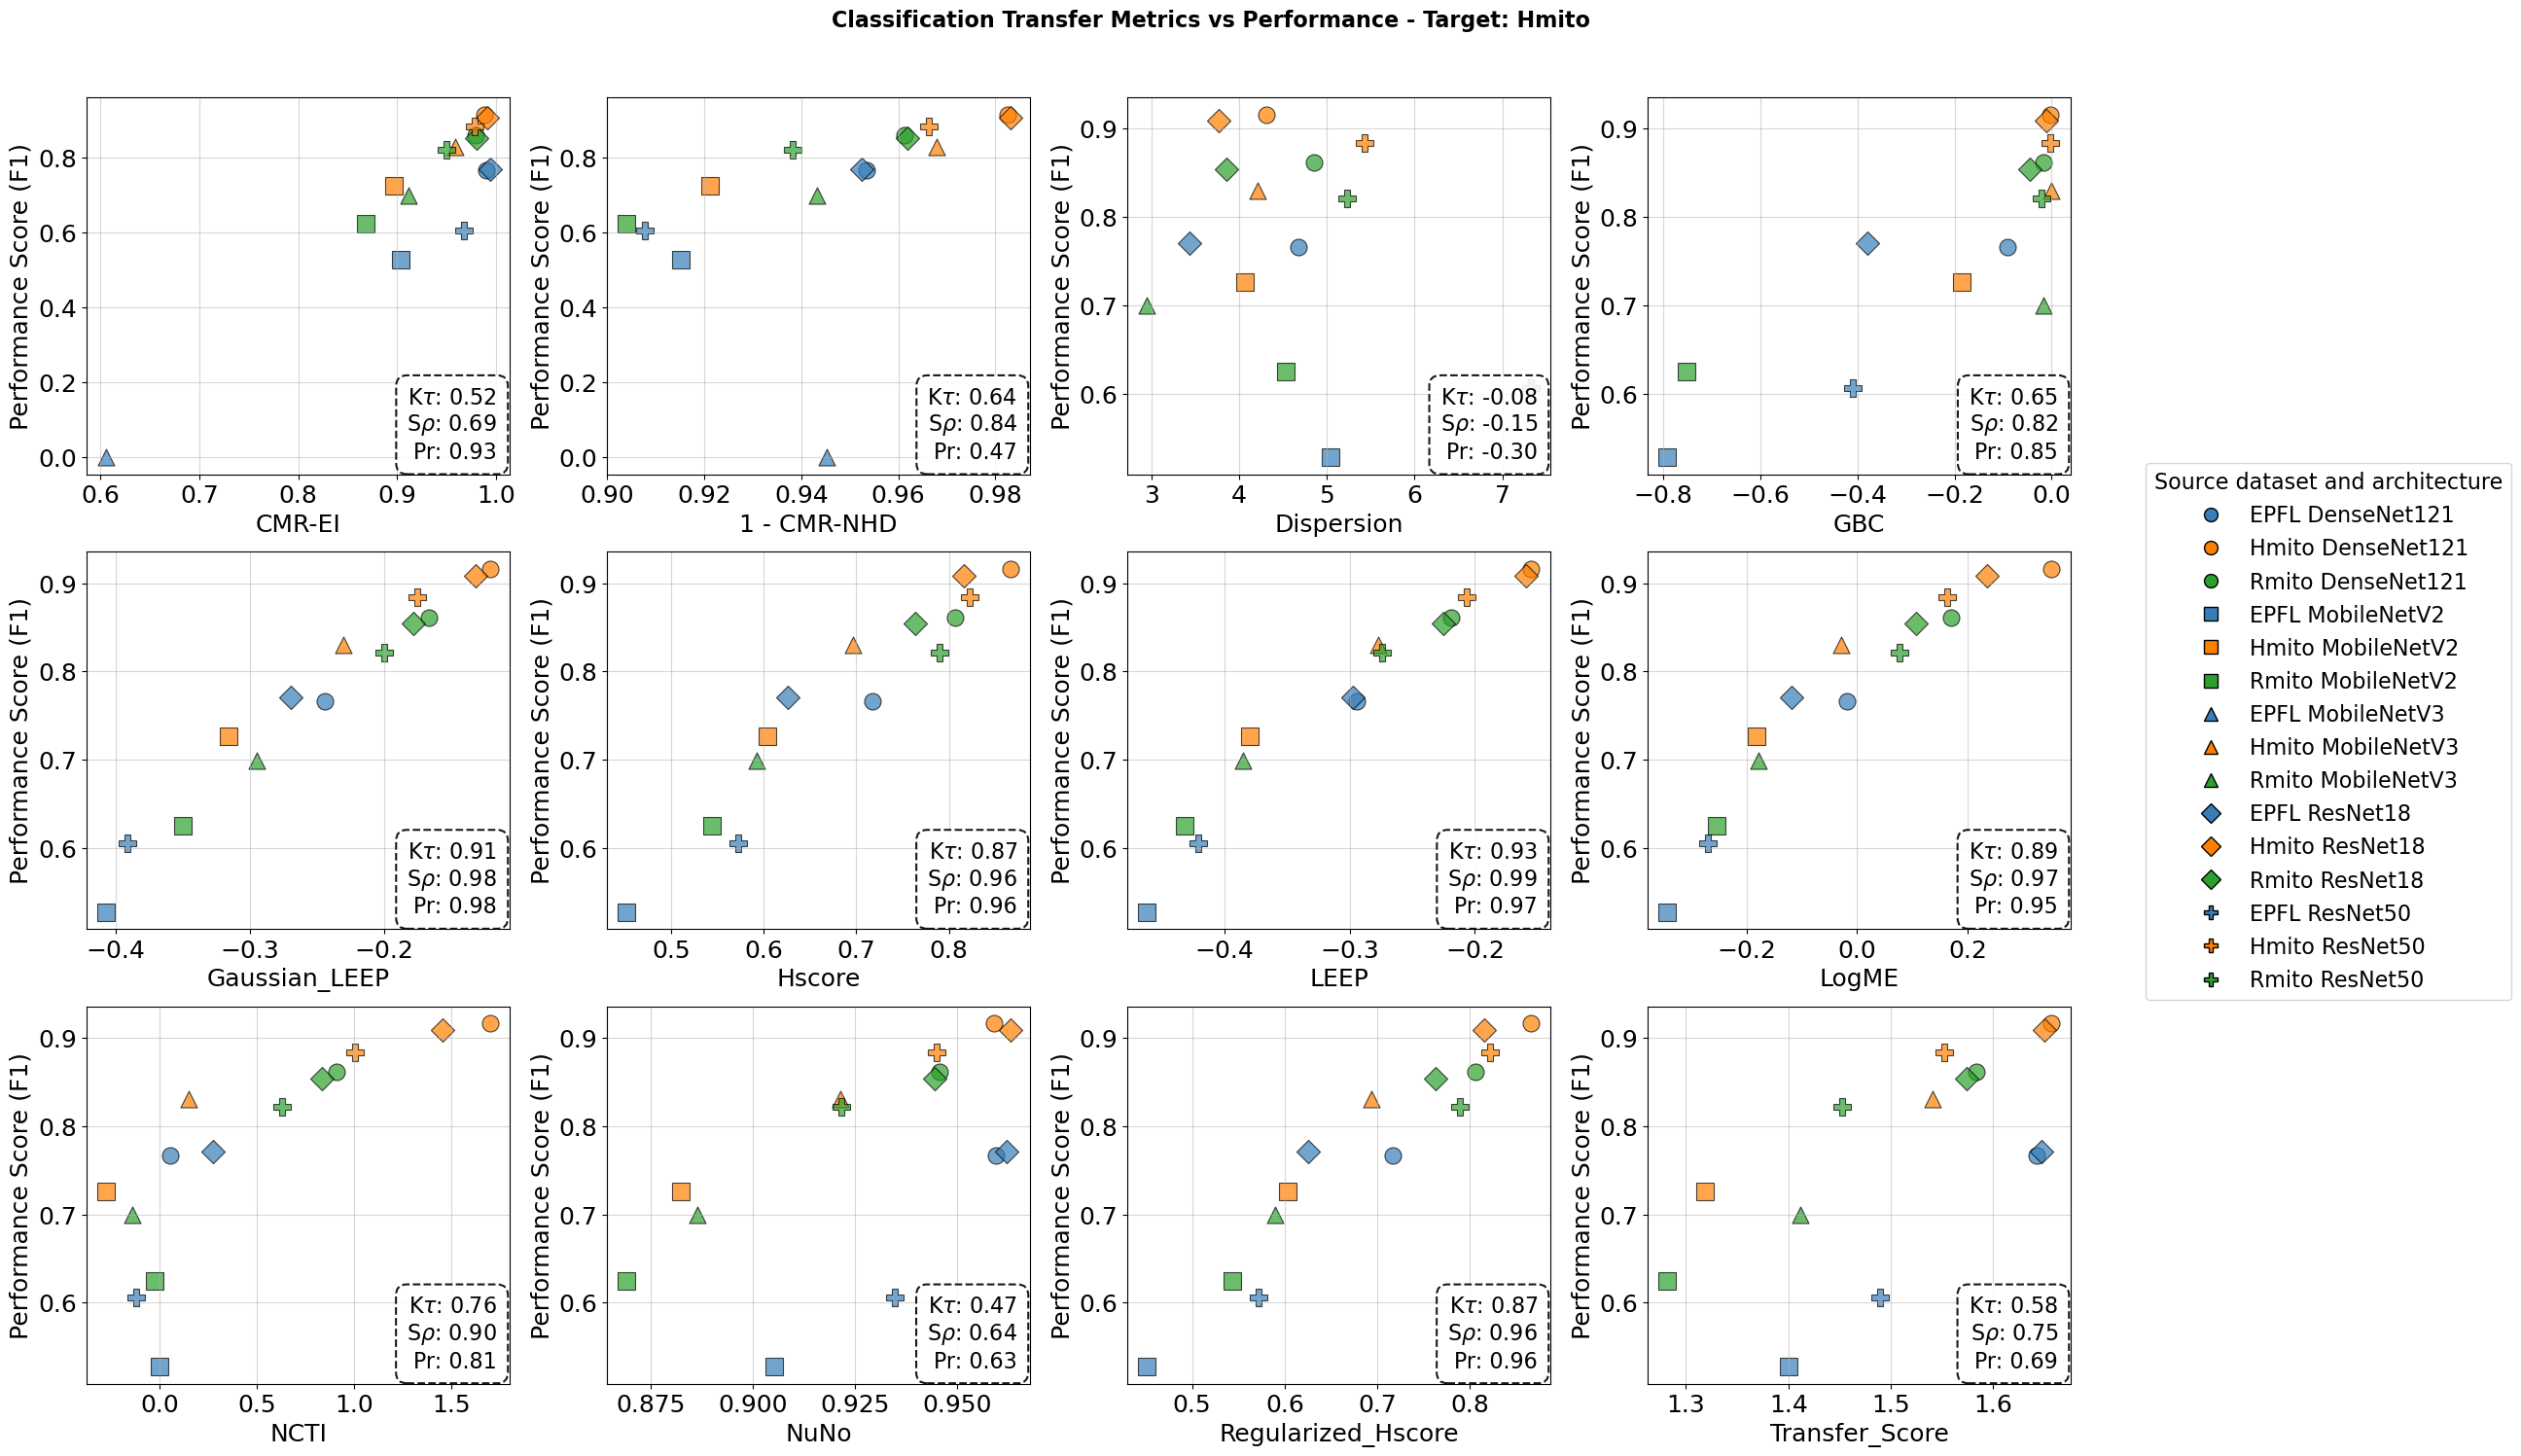

Saved figure to: /g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/extended_005-01/classification_metrics_Rmito.png
Saved figure to: /g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/extended_005-01/classification_metrics_Rmito.svg


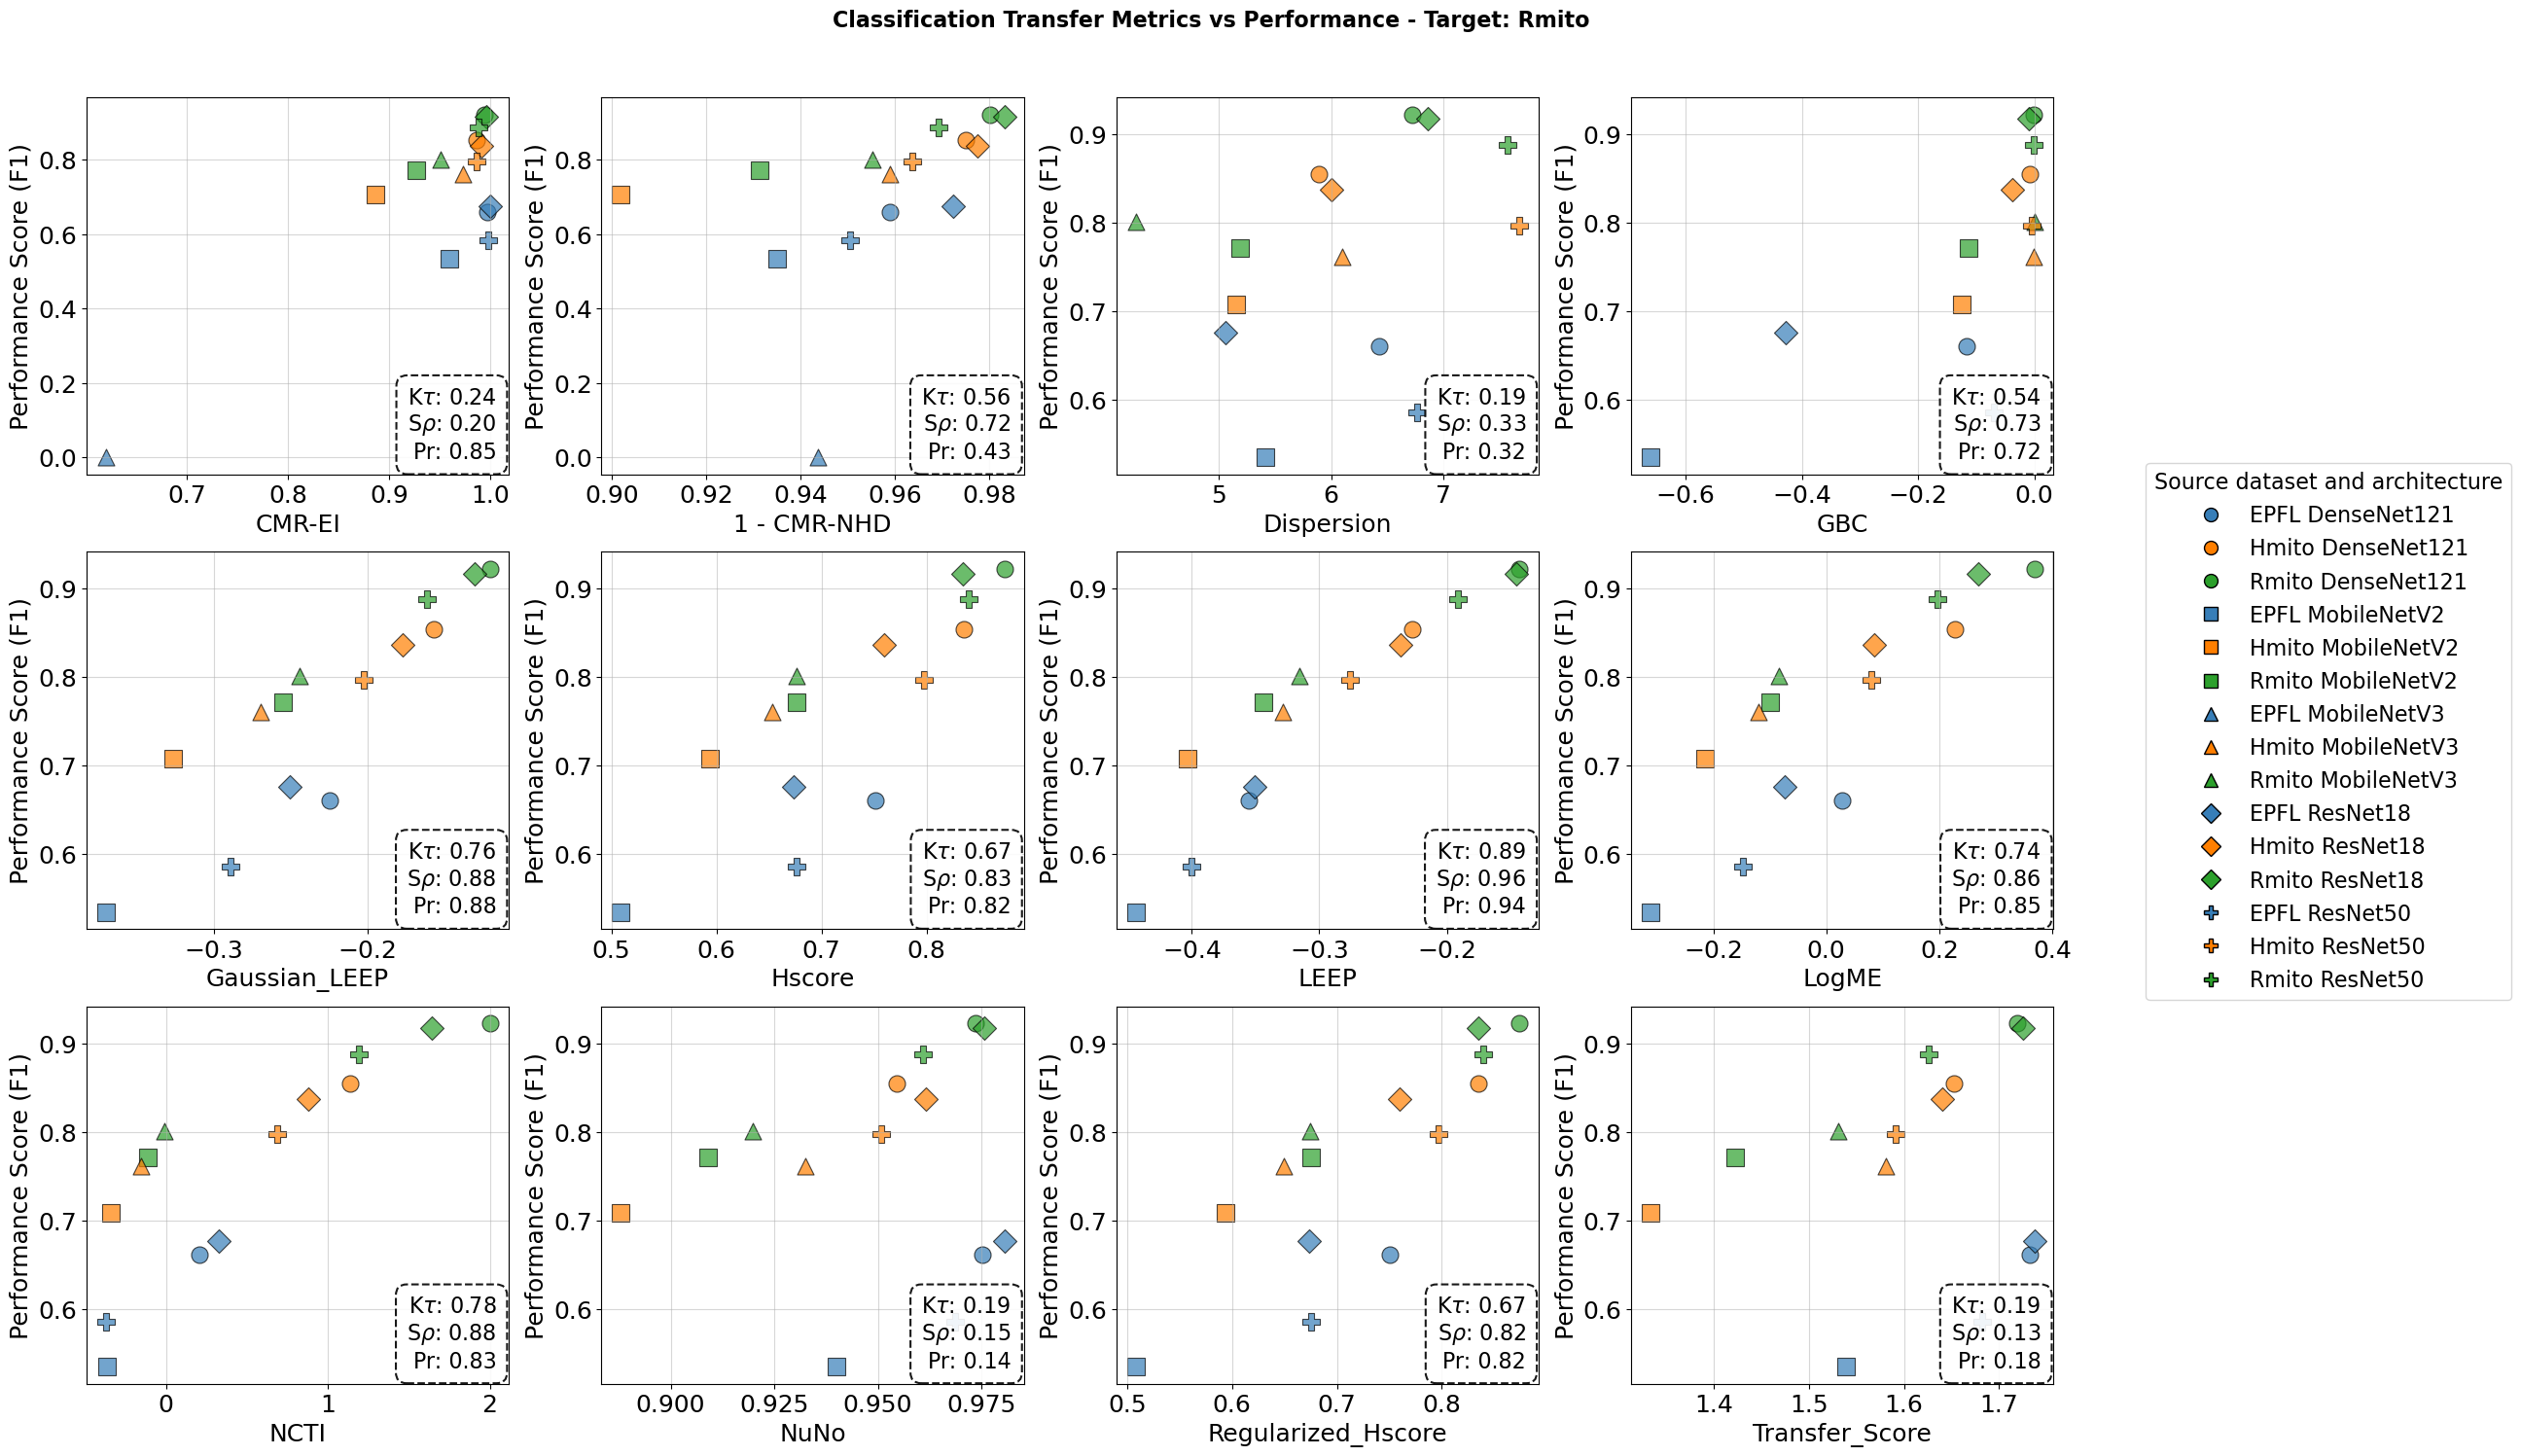

In [5]:
classification_base_path = Path(
    "/g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/fullset_results2"
 )
consis_class_path = Path(
    "/g/kreshuk/talks/sampled_features/classification/mitochondria/transfer_metric_results/consistency/EI"
 )

transfer_metrics: List[str] = [
    "NCTI",
    "LEEP",
    "Gaussian_LEEP",
    "GBC",
    "LogME",
    "Hscore",
    "Regularized_Hscore",
    "Transfer_Score",
    "Dispersion",
    "NuNo",
    "CMR-EI",
    "CMR-NHD",
]

# Optional: define a save path for the figures
# save_path = None
save_path = Path(
    "/g/kreshuk/talks/model_ranking/notebooks/thesis/mitochondria/figures/classification/extended_005-01"
 )

plot_cmb_classification_seg_transfer_metric_correlations_CVPR(
    classification_results_path=classification_base_path,
    transfer_metrics=transfer_metrics,
    nrows=3,
    ncols=4,
    figsize=(25, 15),
    save_path=save_path,
    point_size=150,
    consistency_class_results_path=consis_class_path,
    consis_class_aug_str="a005-01",
    CMR_metric_keys=["EI", "NHD"],
    inverted_transfer_metrics=["CMR-NHD"],
    scores_fontsize=16,
    title_fontsize=20,
    label_fontsize=18,
    ticks_fontsize=18,
    title_bold=False,
    custom_legend_labels=custom_labels,
)